# Calibración de Segmentación PDI (M2) — v2
Compara umbral manual, Otsu y sustracción de fondo sobre un cuadro del video. Cambia `VIDEO` por un video real.

In [1]:
import cv2, numpy as np, matplotlib.pyplot as plt
from m1_adquisicion import cargar_video, verificar_protocolo_captura, leer_cuadro, extraer_cuadros_rgb
from m2_segmentacion import segmentar_sujeto, SegmentadorFondo, modelo_fondo_mediana, dibujar_resultado

VIDEO = 'demo/sentadilla_sintetica.mp4'   # <- cambiar por el video real
info = cargar_video(VIDEO)
print(info)
print(verificar_protocolo_captura(info))

{'ruta': 'demo/sentadilla_sintetica.mp4', 'fps': 30.0, 'ancho': 1280, 'alto': 720, 'n_cuadros': 285, 'duracion_s': 9.5, 'orientacion': 'horizontal'}
{'fps_ok': True, 'resolucion_ok': True, 'duracion_ok': True, 'protocolo_ok': True}


## 1. Umbral manual vs Otsu (método del Hito 1)

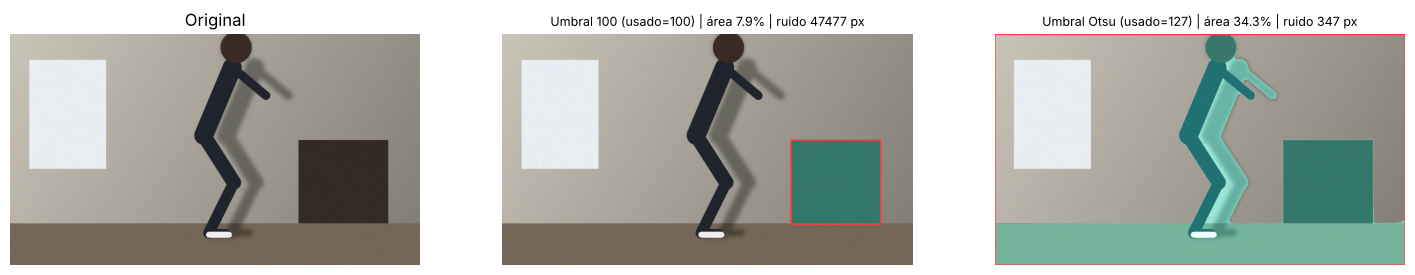

In [2]:
IDX = int(info['n_cuadros'] * 0.4)    # un cuadro con la persona en escena
UMBRAL = 100                            # prueba manual (0-255); None = Otsu
frame = leer_cuadro(VIDEO, IDX)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(frame); ax[0].set_title('Original')
for a, u in zip(ax[1:], [UMBRAL, None]):
    m, bbox, met = segmentar_sujeto(frame, u, devolver_metricas=True)
    a.imshow(dibujar_resultado(frame, m, bbox))
    a.set_title(f"Umbral {'Otsu' if u is None else u} (usado={met['umbral_usado']}) | área {met['area_sujeto_pct']:.1f}% | ruido {met['ruido_fondo_px']} px", fontsize=9)
for a in ax: a.axis('off')
plt.show()

## 2. Sustracción de fondo (recomendado para videos reales)
Requiere ~2 s del encuadre **sin la persona** al inicio del video (propuesta para agregar al protocolo de captura).

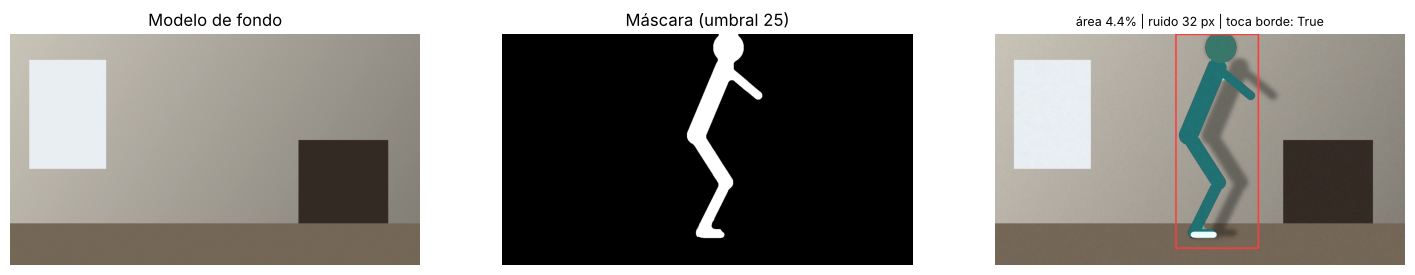

In [3]:
SEG_FONDO = 2.0
n_fondo = int(SEG_FONDO * info['fps'])
vacios = [f for i, f in extraer_cuadros_rgb(VIDEO, max_cuadros=n_fondo)]
fondo = modelo_fondo_mediana(vacios)

UMBRAL_FONDO = 25    # distancia en Lab; subir si aparece ruido, bajar si se pierden partes del cuerpo
seg = SegmentadorFondo(fondo, metodo='diferencia', umbral=UMBRAL_FONDO, suavizado_roi=0)
m, bbox, met = seg.segmentar(frame)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(fondo); ax[0].set_title('Modelo de fondo')
ax[1].imshow(m, cmap='gray'); ax[1].set_title(f'Máscara (umbral {UMBRAL_FONDO})')
ax[2].imshow(dibujar_resultado(frame, m, bbox))
ax[2].set_title(f"área {met['area_sujeto_pct']:.1f}% | ruido {met['ruido_fondo_px']} px | toca borde: {met['toca_borde']}", fontsize=9)
for a in ax: a.axis('off')
plt.show()

## 3. Recorte de la ROI (entrada para M3 / MediaPipe)

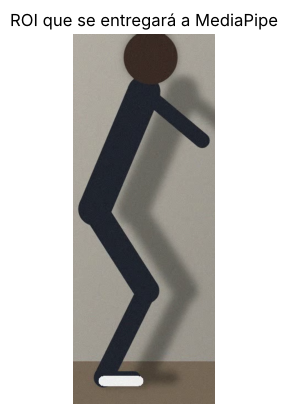

In [4]:
x, y, w, h = bbox
plt.imshow(frame[y:y+h, x:x+w]); plt.axis('off'); plt.title('ROI que se entregará a MediaPipe'); plt.show()